In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent / "src"))
import pandas as pd
import matplotlib.pyplot as plt
import config
from matplotlib.colors import LinearSegmentedColormap
from analysis import weather_links as wl

plt.style.use("seaborn-v0_8-whitegrid")

COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
NO_FIRE, FIRE = COLOURS[0], COLOURS[1]
DIVERGING = LinearSegmentedColormap.from_list(
    "blue_red", ["#184f95", "#6da7ec", "#f0efec", "#ef8a89", "#b8302f"])
INK = "#52514e"
COUNTRY_NAMES = {"KHM": "Cambodia", "LAO": "Laos", "MMR": "Myanmar", "THA": "Thailand", "VNM": "Vietnam"}

In [2]:
sample = wl.sample_cell_days(fraction=0.05)
monthly = wl.monthly_country_weather()

Random sample: 1,795,578 cell-days (5% of each year), 82,283 with fire (4.58%)
Monthly table: 360 rows (5 countries x 72 months)


In [3]:
comparison = wl.compare_fire_days(sample)
comparison

,variable,median_no_fire,median_fire,mean_no_fire,mean_fire,difference_in_sd
0,temp_max_c,29.07,32.43,28.54,32.00,0.77
1,rainfall_7d_mm,34.40,0.96,54.06,7.95,-0.71
2,dry_days,0.00,11.00,6.62,22.71,0.94
3,wind_speed_kmh,4.59,5.18,5.50,5.81,0.10
4,soil_moisture,0.41,0.26,0.37,0.26,-1.12


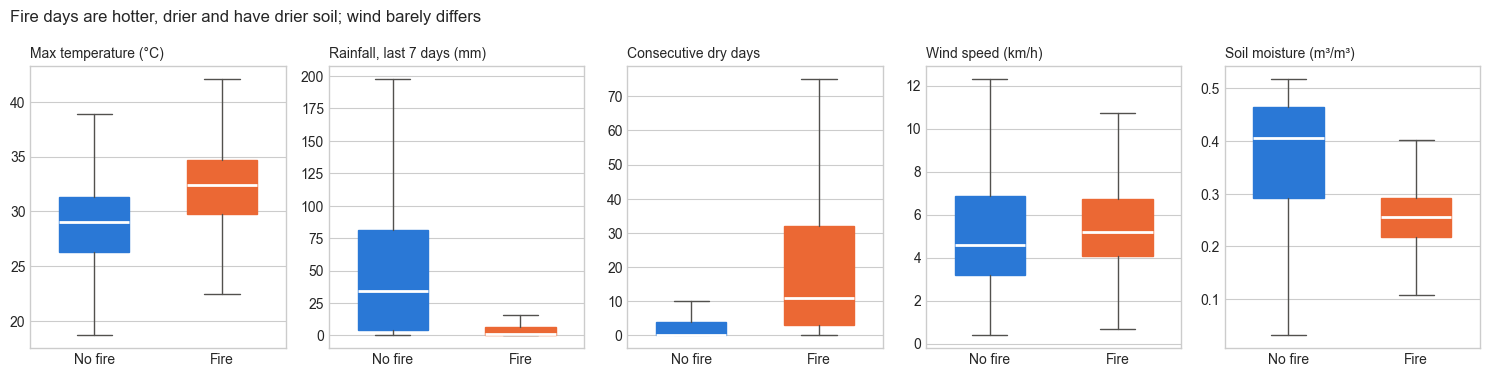

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3.8))
for ax, column in zip(axes, wl.WEATHER_COLUMNS):
    groups = [sample.loc[sample["fire"] == 0, column], sample.loc[sample["fire"] == 1, column]]
    boxes = ax.boxplot(groups, tick_labels=["No fire", "Fire"], widths=0.55, showfliers=False,patch_artist=True, medianprops={"color": "white", "linewidth": 2})
    for patch, colour in zip(boxes["boxes"], [NO_FIRE, FIRE]):
        patch.set_facecolor(colour)
        patch.set_edgecolor(colour)
    for part in ["whiskers", "caps"]:
        for line in boxes[part]:
            line.set_color(INK)
    ax.set_title(wl.WEATHER_LABELS[column], loc="left", fontsize=10)
    ax.grid(axis="x", visible=False)
fig.suptitle("Fire days are hotter, drier and have drier soil; wind barely differs", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.show()

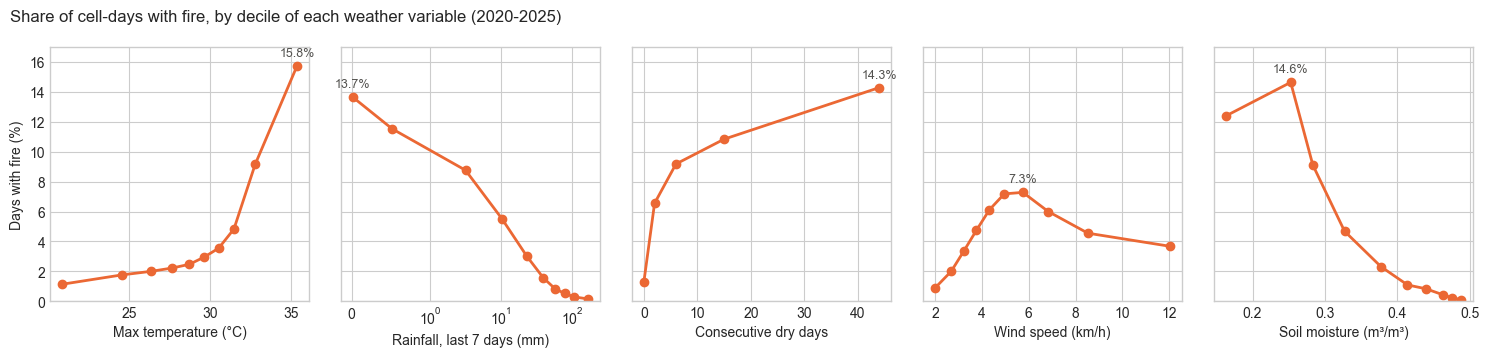

In [5]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3.6), sharey=True)
for ax, column in zip(axes, wl.WEATHER_COLUMNS):
    bins = wl.fire_rate_by_bins(sample, column)
    ax.plot(bins["median_value"], bins["fire_rate_pct"], color=FIRE, linewidth=2, marker="o", markersize=6)
    ax.set_xlabel(wl.WEATHER_LABELS[column])
    highest = bins.loc[bins["fire_rate_pct"].idxmax()]
    ax.annotate(f"{highest['fire_rate_pct']:.1f}%", (highest["median_value"], highest["fire_rate_pct"]), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=9, color=INK)
    if column == "rainfall_7d_mm":
        ax.set_xscale("symlog", linthresh=1)
axes[0].set_ylabel("Days with fire (%)")
axes[0].set_ylim(0, 17)
fig.suptitle("Share of cell-days with fire, by decile of each weather variable (2020-2025)", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
fig.savefig(config.FIGURES_DIR / "fire_rate_by_weather.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
for column in ["rainfall_7d_mm", "wind_speed_kmh"]:
    print(column)
    print(wl.fire_rate_by_bins(sample, column).to_string(index=False))
    print()

rainfall_7d_mm
                            group   rows  fire_days  median_value  fire_rate_pct
(-0.00013000000000000002, 0.0969] 179558      24513      0.012013          13.65
                  (0.0969, 1.441] 179558      20708      0.513337          11.53
                   (1.441, 5.961] 179558      15728      3.138192           8.76
                  (5.961, 16.035] 179557       9921     10.211694           5.53
                 (16.035, 31.095] 179558       5388     23.145538           3.00
                 (31.095, 48.458] 179558       2797     39.540583           1.56
                 (48.458, 67.952] 179557       1495     57.870138           0.83
                 (67.952, 91.555] 179558        933     78.937164           0.52
                (91.555, 129.252] 179558        523    107.076142           0.29
              (129.252, 1820.962] 179558        277    170.054837           0.15

wind_speed_kmh
         group   rows  fire_days  median_value  fire_rate_pct
(0.381, 2.381] 1

In [7]:
correlations = wl.correlation_with_fire(sample)
correlations

,variable,pearson,spearman,strength_rank
0,dry_days,0.196,0.227,1
1,soil_moisture,-0.233,-0.224,2
2,rainfall_7d_mm,-0.149,-0.215,3
3,temp_max_c,0.160,0.170,4
4,wind_speed_kmh,0.020,0.054,5


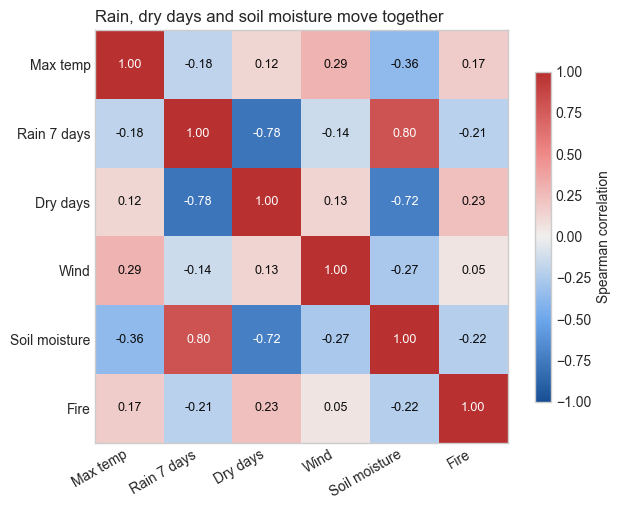

In [8]:
matrix = wl.correlation_matrix(sample)
names = ["Max temp", "Rain 7 days", "Dry days", "Wind", "Soil moisture", "Fire"]

fig, ax = plt.subplots(figsize=(6.5, 5.2))
image = ax.imshow(matrix.values, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(names)))
ax.set_xticklabels(names, rotation=30, ha="right")
ax.set_yticks(range(len(names)))
ax.set_yticklabels(names)
ax.grid(False)
for row in range(len(names)):
    for col in range(len(names)):
        value = matrix.values[row, col]
        colour = "white" if abs(value) > 0.6 else "#0b0b0b"
        ax.text(col, row, f"{value:.2f}", ha="center", va="center", fontsize=9, color=colour)
fig.colorbar(image, ax=ax, label="Spearman correlation", shrink=0.8)
ax.set_title("Rain, dry days and soil moisture move together", loc="left")
plt.tight_layout()
plt.show()

In [9]:
by_month_temp = wl.compare_by_month(sample, "temp_max_c")
by_month_dry = wl.compare_by_month(sample, "dry_days")
by_month_temp.merge(by_month_dry, on=["month", "fire_days_in_sample"], suffixes=("_temp", "_dry_days"))

,month,fire_days_in_sample,median_no_fire_temp,median_fire_temp,median_no_fire_dry_days,median_fire_dry_days
0,1,10013,26.75,29.75,14.0,22.0
1,2,17379,29.08,31.36,7.0,19.0
2,3,26647,32.00,33.43,4.0,13.0
3,4,17737,32.66,34.68,0.0,6.0
4,5,3685,31.21,34.35,0.0,1.0
5,6,587,29.73,32.23,0.0,0.0
6,7,377,29.29,31.96,0.0,0.0
7,8,529,29.08,32.41,0.0,0.0
8,9,339,28.74,30.83,0.0,0.0
9,10,397,28.19,29.19,0.0,0.0


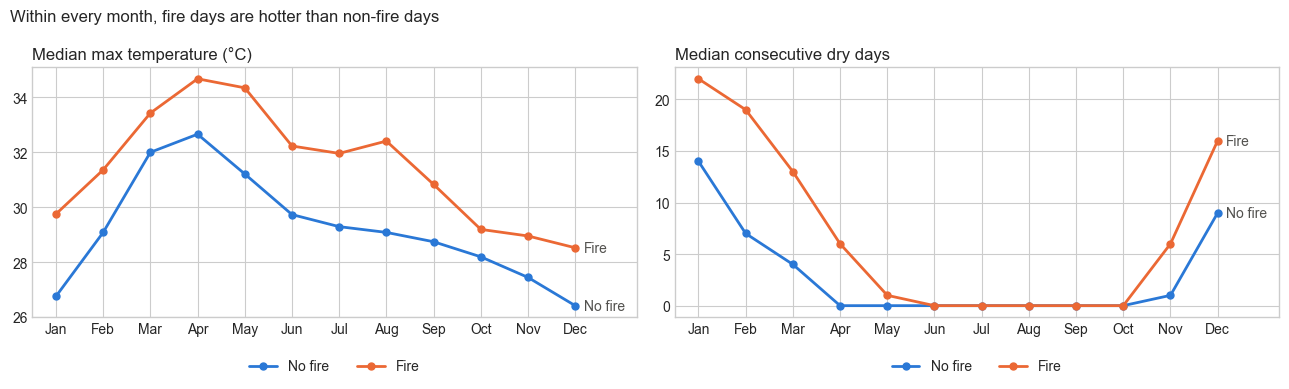

In [10]:
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, table, label in [(axes[0], by_month_temp, "Median max temperature (°C)"),(axes[1], by_month_dry, "Median consecutive dry days")]:
    ax.plot(table["month"], table["median_no_fire"], color=NO_FIRE, linewidth=2, marker="o", markersize=5, label="No fire")
    ax.plot(table["month"], table["median_fire"], color=FIRE, linewidth=2, marker="o", markersize=5, label="Fire")
    ax.set_xticks(table["month"])
    ax.set_xticklabels(month_names)
    ax.set_title(label, loc="left")
    last = table.iloc[-1]
    ax.annotate("Fire", (12, last["median_fire"]), xytext=(6, 0), textcoords="offset points", va="center", color=INK)
    ax.annotate("No fire", (12, last["median_no_fire"]), xytext=(6, 0), textcoords="offset points", va="center", color=INK)
    ax.set_xlim(0.5, 13.3)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
fig.suptitle("Within every month, fire days are hotter than non-fire days", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.show()

In [11]:
dry_season = sample[sample["month"].isin([1, 2, 3, 4])]
print(f"January-April: {len(dry_season):,} cell-days, {int(dry_season['fire'].sum()):,} with fire")
wl.compare_fire_days(dry_season).merge(wl.correlation_with_fire(dry_season)[["variable", "spearman"]], on="variable")

January-April: 591,239 cell-days, 71,776 with fire


,variable,median_no_fire,median_fire,mean_no_fire,mean_fire,difference_in_sd,spearman
0,temp_max_c,30.05,32.63,29.04,32.18,0.56,0.193
1,rainfall_7d_mm,3.54,0.73,14.90,5.47,-0.37,-0.153
2,dry_days,5.00,13.00,16.07,24.81,0.34,0.158
3,wind_speed_kmh,4.85,5.19,5.68,5.79,0.04,0.050
4,soil_moisture,0.28,0.25,0.29,0.25,-0.41,-0.139


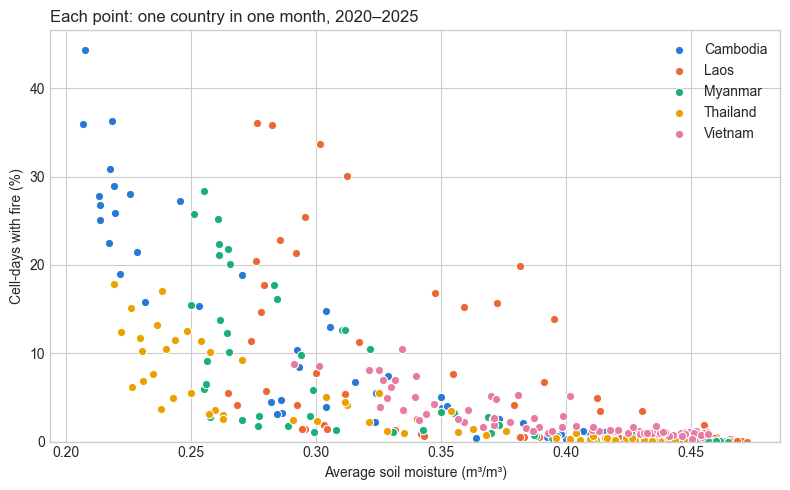

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
for number, country in enumerate(["KHM", "LAO", "MMR", "THA", "VNM"]):
    part = monthly[monthly["country"] == country]
    ax.scatter(part["soil_moisture"], part["fire_rate_pct"], s=36, color=COLOURS[number], edgecolor="white", linewidth=0.8, label=COUNTRY_NAMES[country])
ax.set_xlabel("Average soil moisture (m³/m³)")
ax.set_ylabel("Cell-days with fire (%)")
ax.set_ylim(bottom=0)
ax.set_title("Each point: one country in one month, 2020–2025", loc="left")
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

In [13]:
level_rows = []
for column in wl.WEATHER_COLUMNS:
    country_month = monthly[column].rank().corr(monthly["fire_rate_pct"].rank())
    cell_day = correlations.loc[correlations["variable"] == column, "spearman"].iloc[0]
    level_rows.append({"variable": column, "spearman_cell_day": cell_day, "spearman_country_month": round(country_month, 2)})
pd.DataFrame(level_rows)

,variable,spearman_cell_day,spearman_country_month
0,temp_max_c,0.170,0.32
1,rainfall_7d_mm,-0.215,-0.82
2,dry_days,0.227,0.82
3,wind_speed_kmh,0.054,0.24
4,soil_moisture,-0.224,-0.88


In [14]:
from analysis import risk_score as rs

rs.SCORE_RULES

,component,variable,0 points,1 point,2 points
0,heat_points,temp_max_c,below 30 °C,30 to 34 °C,34 °C or more
1,rain_points,rainfall_7d_mm,more than 20 mm,2 to 20 mm,2 mm or less
2,soil_points,soil_moisture,0.30 or more,below 0.30,-
3,wind_points,wind_speed_kmh,below 3 or above 9 km/h,3 to 9 km/h,-
4,landcover_points,"forest_pct, land_cover_dominant","dense forest, cleared or built-up land","20-90% forest, or mostly grassland",-


In [15]:
scored = rs.add_risk_score(rs.sample_for_scoring())
scored["risk_level"] = rs.risk_level(scored["risk_score"])
scored[["grid_id", "date", "country"] + rs.POINT_COLUMNS + ["risk_score", "risk_level", "fire"]].head()

Random sample: 1,795,578 cell-days (5% of each year), 82,283 with fire (4.58%)


,grid_id,date,country,heat_points,rain_points,soil_points,wind_points,landcover_points,risk_score,risk_level,fire
0,20.4_99.2,2020-05-20,MMR,1,1,0,1,0,3,Medium,0
1,11.7_98.3,2020-08-27,MMR,0,0,0,0,1,1,Low,0
2,18.0_106.1,2020-01-28,VNM,0,0,0,0,0,0,Low,0
3,13.8_102.3,2020-08-12,THA,1,0,0,1,1,3,Medium,0
4,16.4_107.6,2020-10-17,VNM,0,0,0,0,1,1,Low,0


In [16]:
for column in rs.POINT_COLUMNS:
    print(column)
    print(rs.fire_rate_by_group(scored, column).to_string(index=False))
    print()

heat_points
 heat_points  cell_days  fire_days  share_of_cell_days_pct  share_of_fires_pct  fire_rate_pct
           0    1059727      21946                    59.0                26.7           2.07
           1     569248      33679                    31.7                40.9           5.92
           2     166603      26658                     9.3                32.4          16.00

rain_points
 rain_points  cell_days  fire_days  share_of_cell_days_pct  share_of_fires_pct  fire_rate_pct
           0    1025642       9525                    57.1                11.6           0.93
           1     375253      24030                    20.9                29.2           6.40
           2     394683      48728                    22.0                59.2          12.35

soil_points
 soil_points  cell_days  fire_days  share_of_cell_days_pct  share_of_fires_pct  fire_rate_pct
           0    1267727      18005                    70.6                21.9           1.42
           1     52785

In [17]:
by_score = rs.fire_rate_by_group(scored, "risk_score")
by_score

,risk_score,cell_days,fire_days,share_of_cell_days_pct,share_of_fires_pct,fire_rate_pct
0,0,185023,431,10.3,0.5,0.23
1,1,419781,2422,23.4,2.9,0.58
2,2,415784,5719,23.2,7.0,1.38
3,3,276256,9166,15.4,11.1,3.32
4,4,204511,15425,11.4,18.7,7.54
5,5,173485,22340,9.7,27.2,12.88
6,6,96750,19767,5.4,24.0,20.43
7,7,23988,7013,1.3,8.5,29.24


In [18]:
by_level = rs.fire_rate_by_group(scored, "risk_level")
by_level

,risk_level,cell_days,fire_days,share_of_cell_days_pct,share_of_fires_pct,fire_rate_pct
0,Low,1020588,8572,56.8,10.4,0.84
1,Medium,480767,24591,26.8,29.9,5.11
2,High,294223,49120,16.4,59.7,16.69


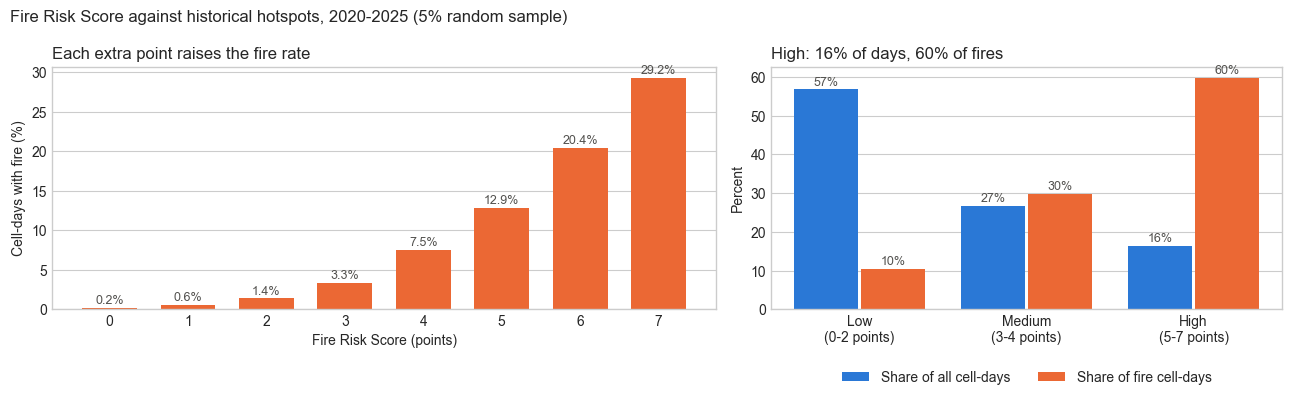

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})

ax = axes[0]
ax.bar(by_score["risk_score"], by_score["fire_rate_pct"], color=FIRE, width=0.7)
for _, row in by_score.iterrows():
    ax.annotate(f"{row['fire_rate_pct']:.1f}%", (row["risk_score"], row["fire_rate_pct"]), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9, color=INK)
ax.set_xticks(by_score["risk_score"])
ax.set_xlabel("Fire Risk Score (points)")
ax.set_ylabel("Cell-days with fire (%)")
ax.set_title("Each extra point raises the fire rate", loc="left")
ax.grid(axis="x", visible=False)

ax = axes[1]
positions = range(len(by_level))
ax.bar([p - 0.2 for p in positions], by_level["share_of_cell_days_pct"], width=0.38, color=NO_FIRE, label="Share of all cell-days")
ax.bar([p + 0.2 for p in positions], by_level["share_of_fires_pct"], width=0.38, color=FIRE, label="Share of fire cell-days")
for p, row in zip(positions, by_level.itertuples()):
    ax.annotate(f"{row.share_of_cell_days_pct:.0f}%", (p - 0.2, row.share_of_cell_days_pct), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9, color=INK)
    ax.annotate(f"{row.share_of_fires_pct:.0f}%", (p + 0.2, row.share_of_fires_pct), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9, color=INK)
ax.set_xticks(list(positions))
ax.set_xticklabels([f"{level}\n({low}-{high} points)" for level, low, high in [("Low", 0, 2), ("Medium", 3, 4), ("High", 5, 7)]])
ax.set_ylabel("Percent")
ax.set_title("High: 16% of days, 60% of fires", loc="left")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
ax.grid(axis="x", visible=False)

fig.suptitle("Fire Risk Score against historical hotspots, 2020-2025 (5% random sample)", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
fig.savefig(config.FIGURES_DIR / "fire_risk_score.png", dpi=150, bbox_inches="tight")
plt.show()

In [20]:
thresholds = rs.compare_thresholds(scored, [(2, 4), (3, 4), (3, 5), (4, 5), (3, 6), (4, 6)])
thresholds

,medium_from,high_from,high_share_of_days_pct,fires_caught_by_high_pct,fire_rate_in_high_pct,fires_missed_in_low_pct,fire_rate_in_low_pct
0,2,4,27.8,78.4,12.94,3.5,0.47
1,3,4,27.8,78.4,12.94,10.4,0.84
2,3,5,16.4,59.7,16.69,10.4,0.84
3,4,5,16.4,59.7,16.69,21.6,1.37
4,3,6,6.7,32.5,22.18,10.4,0.84
5,4,6,6.7,32.5,22.18,21.6,1.37


In [21]:
scored["weather_only"] = scored[["heat_points", "rain_points", "soil_points", "wind_points"]].sum(axis=1)
scored["dryness_three_times"] = scored["risk_score"] + (scored["dry_days"] >= 10).astype("int64")
rs.compare_scores(scored, ["risk_score", "weather_only", "dryness_three_times", "fire_weather_index", "temp_max_c"])

,score,ranking_quality
0,risk_score,0.826
1,weather_only,0.827
2,dryness_three_times,0.825
3,fire_weather_index,0.810
4,temp_max_c,0.734


In [22]:
rs.same_alarm_comparison(scored, ["fire_weather_index"])

,method,days_flagged_pct,fires_caught_pct
0,risk score: High,16.4,59.7
1,top fire_weather_index,16.4,52.0


In [23]:
by_year = rs.fire_rate_by_group(scored, ["year", "risk_level"])
by_year.pivot(index="year", columns="risk_level", values="fire_rate_pct")

risk_level,Low,Medium,High
year,,,
2020,0.79,5.53,18.86
2021,1.02,5.24,16.63
2022,1.07,4.44,12.55
2023,0.86,6.30,18.31
2024,0.59,4.46,16.17
2025,0.67,4.62,15.64


In [24]:
by_country = rs.fire_rate_by_group(scored, ["country", "risk_level"])
by_country.pivot(index="country", columns="risk_level", values="fire_rate_pct")

risk_level,Low,Medium,High
country,,,
KHM,0.67,6.10,24.77
LAO,1.76,8.52,23.35
MMR,0.54,5.46,18.57
THA,0.46,3.57,11.23
VNM,1.26,4.08,9.46


In [25]:
monthly_risk = rs.monthly_risk_vs_fire(scored)
print("Spearman, share of High days vs fire rate (12 months):", round(monthly_risk["high_share_pct"].rank().corr(monthly_risk["fire_rate_pct"].rank()), 2))
monthly_risk

Spearman, share of High days vs fire rate (12 months): 0.97


,month,high_share_pct,mean_score,fire_rate_pct
0,1,30.7,3.59,6.54
1,2,38.2,3.75,12.51
2,3,49.0,4.13,17.53
3,4,39.2,3.66,12.05
4,5,13.0,2.43,2.42
5,6,1.8,1.72,0.40
6,7,0.8,1.50,0.25
7,8,0.7,1.48,0.35
8,9,0.1,1.29,0.23
9,10,0.5,1.43,0.26


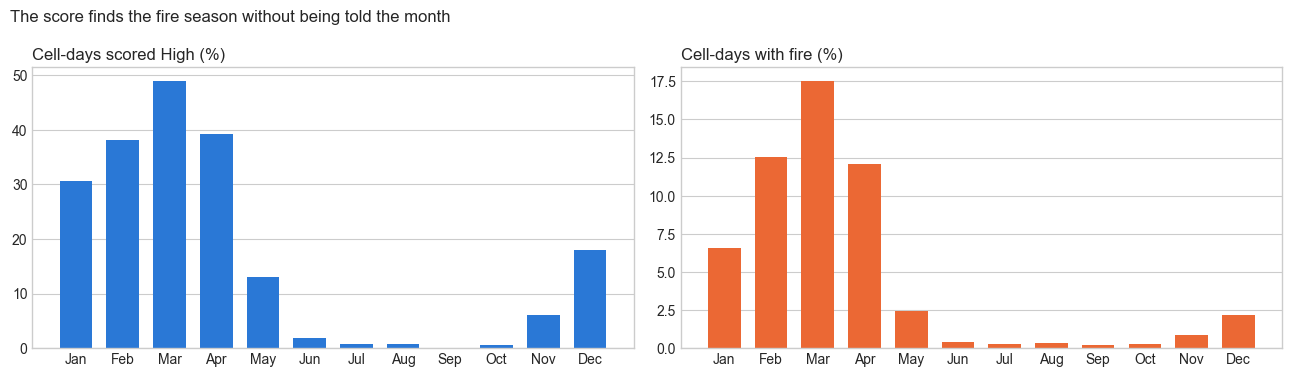

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharex=True)
for ax, column, colour, label in [(axes[0], "high_share_pct", NO_FIRE, "Cell-days scored High (%)"), (axes[1], "fire_rate_pct", FIRE, "Cell-days with fire (%)")]:
    ax.bar(monthly_risk["month"], monthly_risk[column], color=colour, width=0.7)
    ax.set_xticks(monthly_risk["month"])
    ax.set_xticklabels(month_names)
    ax.set_title(label, loc="left")
    ax.grid(axis="x", visible=False)
fig.suptitle("The score finds the fire season without being told the month", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.show()

In [27]:
example = scored[(scored["risk_level"] == "High") & (scored["fire"] == 1)].iloc[0]
print(example["grid_id"], example["date"].date(), example["country"])
rs.explain_score(example)

19.1_95.7 2020-02-18 MMR


,component,value,points
0,heat_points,32.81,1
1,rain_points,0.01,2
2,soil_points,0.25,1
3,wind_points,8.79,1
4,landcover_points,"80.91, forest",1
5,risk_score,High,6
